In [ ]:
import numpy as np
import pandas as  pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


In [ ]:
import os


print(os.listdir(path))

csv_path = os.path.join(path, "AB_NYC_2019.csv")
df = pd.read_csv(csv_path)



['AB_NYC_2019.csv', 'New_York_City_.png']


In [ ]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df.shape

(48895, 16)

In [ ]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [ ]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [ ]:
df['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

In [ ]:
df["room_type"].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


<Axes: xlabel='room_type', ylabel='count'>

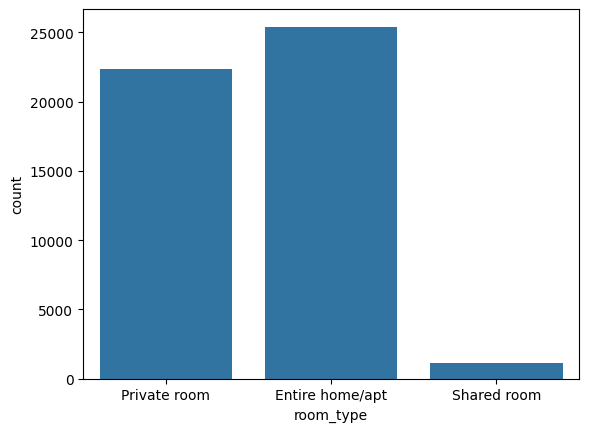

In [ ]:
sns.countplot(x = 'room_type',data = df)

In [ ]:
numerical_cols = df.select_dtypes(include='number')

In [ ]:
numerical_cols.drop(['id','host_id'],axis = 1,inplace=True)

array([[<Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'price'}>],
       [<Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>, <Axes: >]],
      dtype=object)

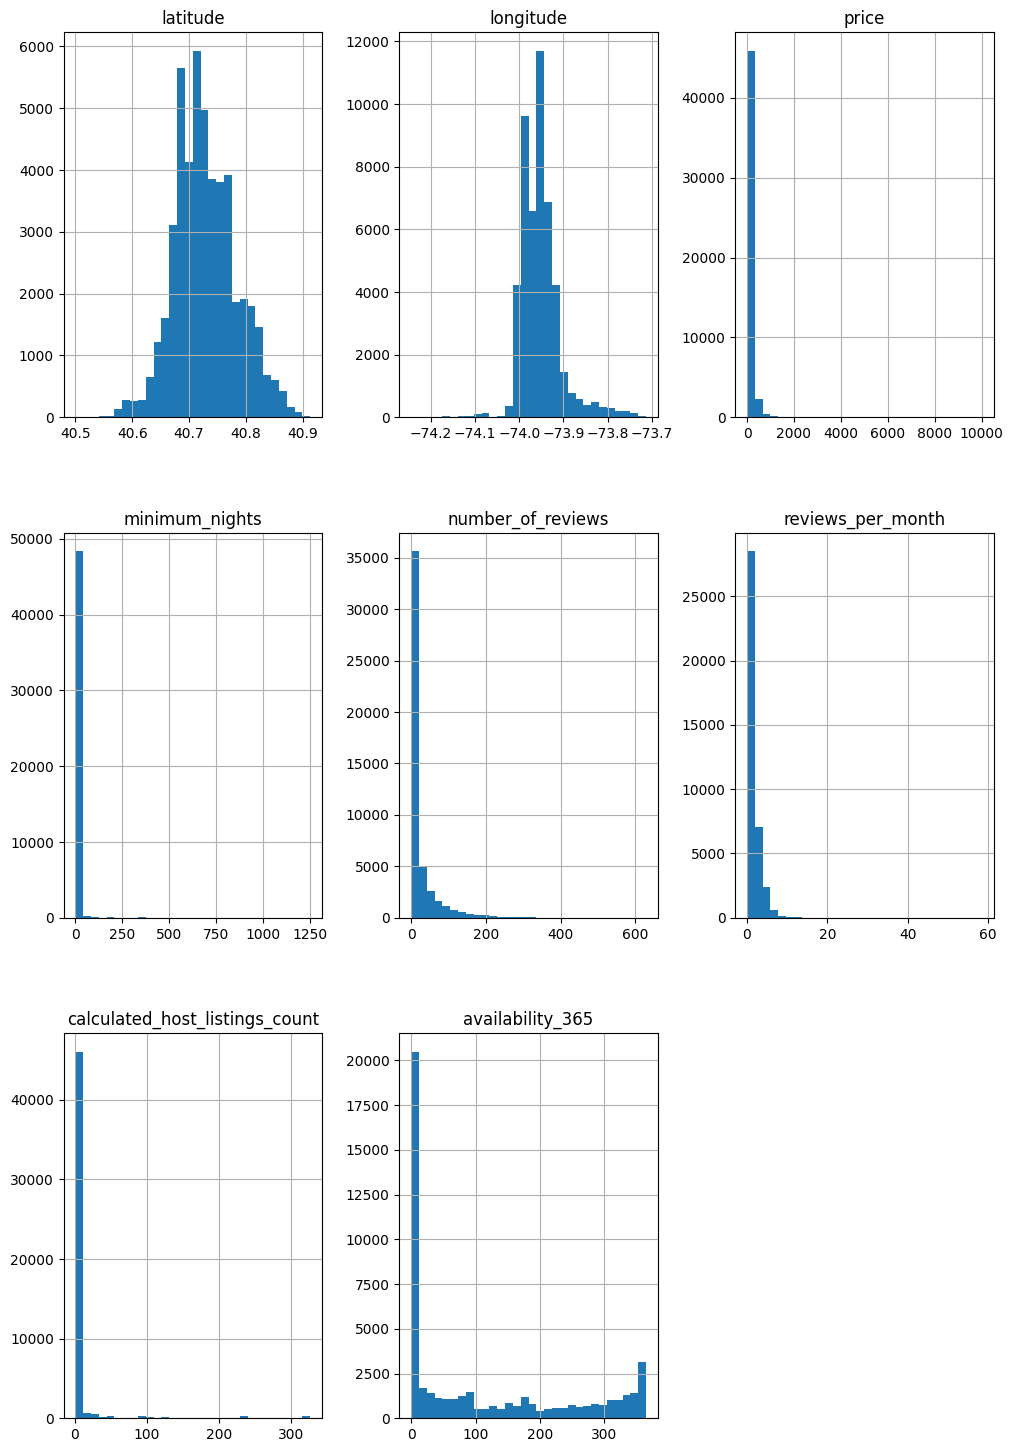

In [ ]:
numerical_cols.hist(bins=30, figsize=(12, 18))


<Axes: xlabel='neighbourhood_group', ylabel='count'>

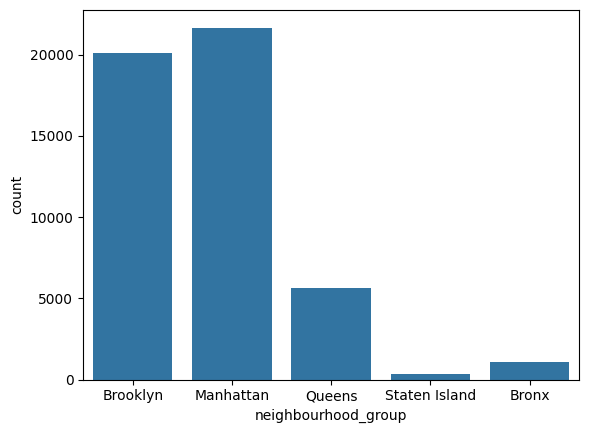

In [ ]:
sns.countplot(data = df,x = 'neighbourhood_group')

<Axes: xlabel='room_type', ylabel='price'>

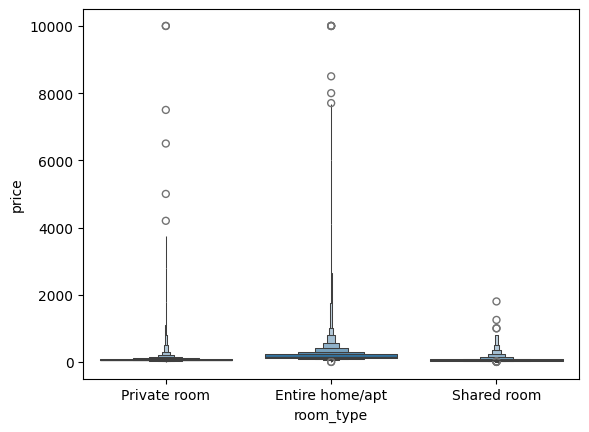

In [ ]:
sns.boxenplot(x = 'room_type',y = 'price',data = df)

In [ ]:
corr = numerical_cols.drop(columns=['latitude', 'longitude']).corr()

In [ ]:
corr = numerical_cols.corr()

In [ ]:
corr

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
latitude,1.000000,0.084788,0.033939,0.024869,-0.015389,-0.010142,0.019517,-0.010983
longitude,0.084788,1.000000,-0.150019,-0.062747,0.059094,0.145948,-0.114713,0.082731
price,0.033939,-0.150019,1.000000,0.042799,-0.047954,-0.030608,0.057472,0.081829
minimum_nights,0.024869,-0.062747,0.042799,1.000000,-0.080116,-0.121702,0.127960,0.144303
number_of_reviews,-0.015389,0.059094,-0.047954,-0.080116,1.000000,0.549868,-0.072376,0.172028
reviews_per_month,-0.010142,0.145948,-0.030608,-0.121702,0.549868,1.000000,-0.009421,0.185791
calculated_host_listings_count,0.019517,-0.114713,0.057472,0.127960,-0.072376,-0.009421,1.000000,0.225701
availability_365,-0.010983,0.082731,0.081829,0.144303,0.172028,0.185791,0.225701,1.000000


<Axes: >

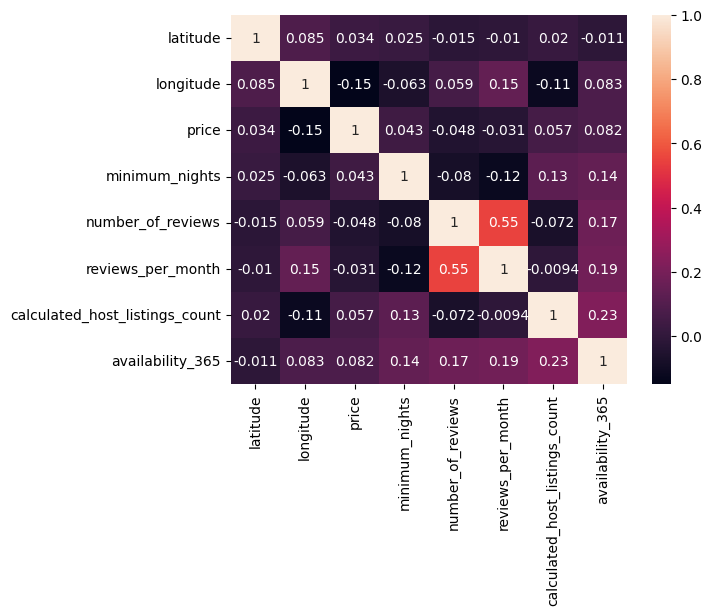

In [ ]:
sns.heatmap(corr,annot=True)

<Axes: xlabel='longitude', ylabel='latitude'>

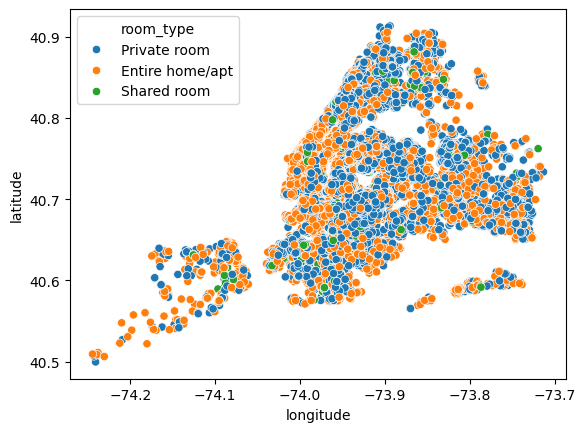

In [ ]:
sns.scatterplot(x='longitude', y='latitude',data=df,hue = 'room_type')

In [ ]:
df_cleaned = df.drop(columns=['id','host_id','name','host_name','last_review'])

In [ ]:
df_cleaned['reviews_per_month'] = df_cleaned['reviews_per_month'].fillna(0)

In [ ]:
price_cap = df_cleaned['price'].quantile(0.99)
nights_cap = df_cleaned['minimum_nights'].quantile(0.99)


df_cleaned['price'] = df_cleaned['price'].clip(upper=price_cap)
df_cleaned['minimum_nights'] = df_cleaned['minimum_nights'].clip(upper=nights_cap)

In [ ]:
X = df_cleaned.drop(columns=['room_type'])
y = df_cleaned['room_type']

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)


In [ ]:
df_cleaned[numerical_cols].skew()

,0
latitude,0.237167
longitude,1.284210
price,2.776321
minimum_nights,2.360347
number_of_reviews,3.690635
reviews_per_month,3.300723
calculated_host_listings_count,7.933174
availability_365,0.763408


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder,PowerTransformer
from sklearn.compose import ColumnTransformer

In [ ]:
numerical_cols = ["latitude", "longitude"]
skew_cols = [
    "price", "minimum_nights", "number_of_reviews",
    "reviews_per_month", "calculated_host_listings_count", "availability_365"
]
categorical_cols = ['neighbourhood_group', 'neighbourhood']

# 1 numerical pipeline (without PowerTransformer)
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

# 2 skew pipeline
skew_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(method='yeo-johnson', standardize=True)),
    ('scale', StandardScaler())
])

# 3 categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numerical', numeric_pipeline, numerical_cols),
    ('skew', skew_pipeline, skew_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

preprocessor

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['latitude', 'longitude']),
                                ('skew',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('power', PowerTransformer()),
                                                 ('scale', StandardScaler())]),
                                 ['price', 'minimum_nights',
                                  'number_of_reviews', 'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

In [ ]:
from sklearn. linear_model import LogisticRegression
from sklearn. tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [ ]:
models = {
    'Logistic Regression' : LogisticRegression(class_weight='balanced', random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest'       : RandomForestClassifier(class_weight='balanced', random_state=42),
    'Gradient Boosting'   : GradientBoostingClassifier(random_state=42)
}

In [ ]:
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])

    accuracy = cross_val_score(pipe, X_train, y_train, cv=3, scoring='accuracy')
    macro_f1 = cross_val_score(pipe, X_train, y_train, cv=3, scoring='f1_macro')

    print(f"{name} -> Accuracy: {accuracy.mean():.3f} , F1: {macro_f1.mean():.3f}")

Logistic Regression -> Accuracy: 0.730 , F1: 0.579
Decision Tree -> Accuracy: 0.785 , F1: 0.650
Random Forest -> Accuracy: 0.852 , F1: 0.714
Gradient Boosting -> Accuracy: 0.850 , F1: 0.708


In [ ]:
from sklearn.model_selection import RandomizedSearchCV


best_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',RandomForestClassifier(class_weight='balanced'))
])


param_distribution ={

"classifier__n_estimators" : [100,200,150,300],
"classifier__max_depth": [8, 12, 15, 20, None],
"classifier__min_samples_split": [2, 5, 10]
}


search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distribution,
    n_iter=10,
    cv = 3,
    scoring = 'f1_macro',
    random_state=42

)



search.fit(X_train,y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scale',
                                                                                                StandardScaler())]),
                                                                               ['latitude',
                                                                                'longitude']),
                                                                              ('skew',
                                                                               Pipeline(steps=[('impute',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('power',
                                                                                                PowerTransformer()),
                                                                                               ('scale',
                                                                                                StandardScaler())]...
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('encode',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classifier',
                                              RandomForestClassifier(class_weight='balanced'))]),
                   param_distributions={'classifier__max_depth': [8, 12, 15, 20,
                                                                  None],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     150,
                                                                     300]},
                   random_state=42, scoring='f1_macro')

In [ ]:
print("Best Parameters: ", search. best_params_)
print("Best CV Macro-F1: ", search. best_score_)

Best Parameters:  {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__max_depth': None}
Best CV Macro-F1:  0.7376030676272908


In [113]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

best_pipeline = search.best_estimator_
y_pred = best_pipeline.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro F1 Score: {f1_score(y_test, y_pred, average='macro'):.3f}")


Accuracy Score: 0.858
Macro F1 Score: 0.749


In [114]:
import joblib
joblib.dump(best_pipeline, "Model_Pipeline.pkl")

['Model_Pipeline.pkl']